# MSCS 634 - Lab Assignment 2
## K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) Classifiers on the Wine Dataset

**Student Name:** Sam Sheu  
**Course:** MSCS 634 - Advanced Big Data and Data Mining  
**Lab Assignment:** Lab 2 - KNN & RNN Classifier Analysis

---

### Objective
In this lab, we explore the performance of **K-Nearest Neighbors (KNN)** and **Radius Neighbors (RNN)** classifiers using the Wine Dataset from scikit-learn. The dataset consists of three classes of wine with various chemical properties as features. By applying KNN and RNN models, we will analyze the impact of different parameter values on model accuracy, visualize key results, and discuss when each model is preferable.

## Step 1: Load and Prepare the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

np.random.seed(42)

In [2]:
# Load the Wine Dataset
wine = load_wine()
X = wine.data
y = wine.target

# Convert to DataFrame for easier exploration
df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y
df['class_name'] = [wine.target_names[i] for i in y]

print('Shape of dataset:', df.shape)
print('Number of features:', len(wine.feature_names))
print('Number of classes:', len(wine.target_names))
print('Class names:', wine.target_names)
df.head()

Shape of dataset: (178, 15)
Number of features: 13
Number of classes: 3
Class names: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
# Feature details
print('Feature names:')
for i, name in enumerate(wine.feature_names):
    print(f'  {i+1}. {name}')

print('\nStatistical summary:')
df.iloc[:, :-2].describe()

Feature names:
  1. alcohol
  2. malic_acid
  3. ash
  4. alcalinity_of_ash
  5. magnesium
  6. total_phenols
  7. flavanoids
  8. nonflavanoid_phenols
  9. proanthocyanins
  10. color_intensity
  11. hue
  12. od280/od315_of_diluted_wines
  13. proline

Statistical summary:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


Class distribution:
class_name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


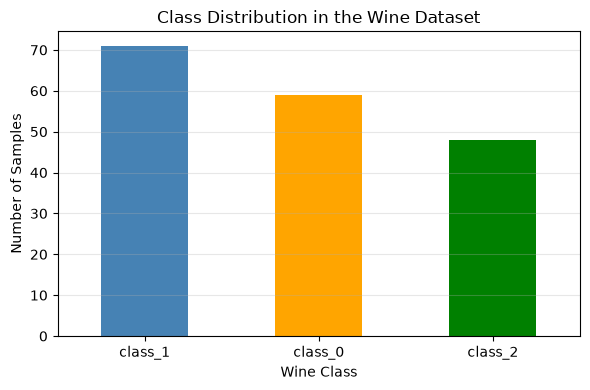

In [4]:
# Class distribution
class_counts = df['class_name'].value_counts()
print('Class distribution:')
print(class_counts)

plt.figure(figsize=(6, 4))
class_counts.plot(kind='bar', color=['steelblue', 'orange', 'green'])
plt.title('Class Distribution in the Wine Dataset')
plt.xlabel('Wine Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Split the dataset: 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set size: {X_train.shape[0]} samples')
print(f'Testing set size:  {X_test.shape[0]} samples')

Training set size: 142 samples
Testing set size:  36 samples


## Step 2: Implement K-Nearest Neighbors (KNN)

We train a `KNeighborsClassifier` for each value of `k` in {1, 5, 11, 15, 21} and record the accuracy on the test set.

In [6]:
k_values = [1, 5, 11, 15, 21]
knn_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    knn_accuracies.append(acc)
    print(f'KNN (k={k:2d}) -> Accuracy: {acc:.4f}')

knn_results = pd.DataFrame({'k': k_values, 'Accuracy': knn_accuracies})
knn_results

KNN (k= 1) -> Accuracy: 0.7778
KNN (k= 5) -> Accuracy: 0.8056
KNN (k=11) -> Accuracy: 0.8056
KNN (k=15) -> Accuracy: 0.8056
KNN (k=21) -> Accuracy: 0.8056


,k,Accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


## Step 3: Implement Radius Neighbors (RNN)

We train a `RadiusNeighborsClassifier` for each radius in {350, 400, 450, 500, 550, 600}. Because some points might not have any neighbors within a given radius, we use `outlier_label='most_frequent'` to make sure prediction still works.

In [7]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_accuracies = []

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
    rnn.fit(X_train, y_train)
    y_pred = rnn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    rnn_accuracies.append(acc)
    print(f'RNN (radius={r}) -> Accuracy: {acc:.4f}')

rnn_results = pd.DataFrame({'Radius': radius_values, 'Accuracy': rnn_accuracies})
rnn_results

RNN (radius=350) -> Accuracy: 0.7222
RNN (radius=400) -> Accuracy: 0.6944
RNN (radius=450) -> Accuracy: 0.6944
RNN (radius=500) -> Accuracy: 0.6944
RNN (radius=550) -> Accuracy: 0.6667
RNN (radius=600) -> Accuracy: 0.6667


,Radius,Accuracy
0,350,0.722222
1,400,0.694444
2,450,0.694444
3,500,0.694444
4,550,0.666667
5,600,0.666667


## Step 4: Visualize and Compare Results

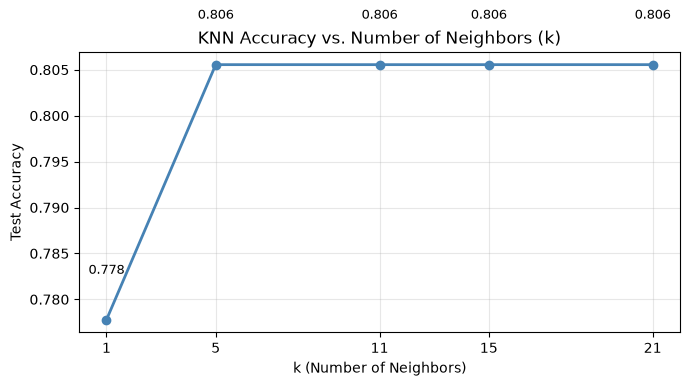

In [8]:
# KNN Accuracy Trend
plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_accuracies, marker='o', linestyle='-', color='steelblue', linewidth=2)
for k, acc in zip(k_values, knn_accuracies):
    plt.text(k, acc + 0.005, f'{acc:.3f}', ha='center', fontsize=9)
plt.title('KNN Accuracy vs. Number of Neighbors (k)')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Test Accuracy')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

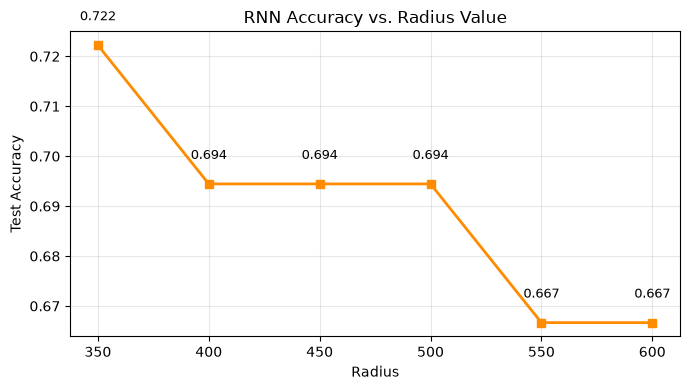

In [9]:
# RNN Accuracy Trend
plt.figure(figsize=(7, 4))
plt.plot(radius_values, rnn_accuracies, marker='s', linestyle='-', color='darkorange', linewidth=2)
for r, acc in zip(radius_values, rnn_accuracies):
    plt.text(r, acc + 0.005, f'{acc:.3f}', ha='center', fontsize=9)
plt.title('RNN Accuracy vs. Radius Value')
plt.xlabel('Radius')
plt.ylabel('Test Accuracy')
plt.xticks(radius_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observations and Discussion

### KNN Observations
- 77.78% accuracy when k = 1 is the lowest of the KNN runs. In machine learning, it means the model is sensitive to noise. It memorizes the exact details of training data but fails misearbly when exposed to new data. 

- For k = 5, 11, 15, and 21, the model plateaued at 80.56% accuracy. Increasing `k` beyond a certain point smoothed the decision boundary without hurting accuracy on this test set, indicating that the Wine dataset is dense enough (178 samples across 3 classes) that mid-range `k` values are all reasonable.

### RNN Observations
- Radius Neighbors classification depends on the distance scale of the features. Because `proline` values reach into the thousands while other features are near 1, the effective distance between points is dominated by that one feature.
- The accuracy decreased when the radius grew. Larger radii will capture nearly the entire training set. Therefore, the majur class, which is class 1, will dominant the results, and it leads to declining accuracy curve.

### KNN vs. RNN Comparison
Both algorithms can perform poorly when they encounter a dataset in which the features have very different scales or the number of features is too large. Features with larger numerical ranges can dominate the distance calculation, while too many features can make it difficult to determine which data points are truly close to one another. Looking back at the Wine Dataset, it contains 13 numerical features with noticeably different scales. For example, alcohol values are relatively small, while proline values can reach into the hundreds or thousands. Therefore, both KNN and RNN may be strongly influenced by large-scale features unless the data is standardized. Although 13 features is not extremely high-dimensional, unnecessary or strongly correlated features can still reduce the reliability of distance-based classification.

For KNN, the selection of the k value has a major effect on performance. When k is too small, the model may perform very well on the training data but become sensitive to noise and individual samples, causing unstable predictions on new testing data. This is a form of overfitting. However, when k is too large, the model considers many distant neighbors, which may cause important local patterns to be ignored and lead to underfitting. KNN can also struggle when the dataset has areas with different densities. Because KNN must always find a fixed number of neighbors, it may include distant and less relevant samples simply to obtain the required number of neighbors.

For RNN, the radius determines which training samples are included in the classification decision. If the radius is too large, almost all training samples may be included. In this situation, the model may predict according to the most common class in the entire dataset rather than using the samples that are truly close to the new data point. If the radius is too small, some testing samples may have no neighbors and therefore cannot be classified. However, this behavior can also make RNN useful for identifying outliers or anomalies. When a new data point is located in an empty region with no training samples inside the defined radius, RNN can reject the point or leave it unclassified instead of forcing a potentially unreliable prediction.

Overall, KNN is usually more dependable when every sample must receive a prediction because it always selects a fixed number of neighbors. RNN is more useful when distance itself has meaningful importance and when the model should avoid classifying isolated or unusual samples. However, both algorithms depend heavily on feature scaling, data density, and careful parameter selection.
